## Illustrative example of $\chi^2$ minimisation in Python - do not use this approach to fit your data!

This notebook provides a minimal illustrative example of how a chi-squared minimisation could be implemented in Python. 

It is not recommended that you use this exact approach for your own data analysis, as it is inefficient and prone to errors when using anything but the simplest functional forms - instead use the `scipy.optimize.curve_fit` function (which uses chi-squared minimisation internally in a more efficient and robust manner), as outlined in a separate notebook, `example_curve_fit.ipynb`. The point of this example is that it shows explicity how a 'fit' is done by minimizing chi-squared - as you have done in Skills session 2 using Excel.



---


We import some common modules that we need to use:

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy
import scipy.optimize
import scipy.stats

We will enter our data as a set of `numpy` arrays. We have our data values for x (independent variable) and y (dependent variable), and error in y values. These are the arrays `x_values`, `y_values` and `y_errors`, respectively. As good physicists, one of the things that we are trained to do is to **plot** our data as we go. Let's make a simple matplotlib graph to show our data and error bars:

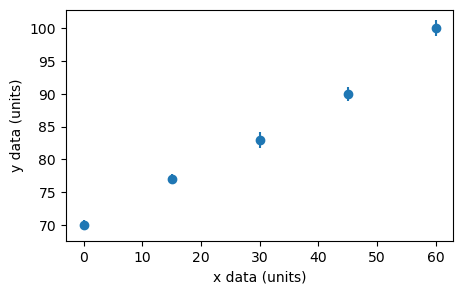

In [16]:
x_values = numpy.array([0, 15, 30, 45, 60])
y_values = numpy.array([70, 77, 83, 90, 100])
y_errors = numpy.array([0.8, 0.7, 1.2, 1.1, 1.2])


plt.figure(figsize=(5,3))
plt.errorbar(x_values, 
             y_values, 
             yerr=y_errors, # use y_errors array for y error bars
             marker='o',    # circular markers at each datapoint
             linestyle='None') # no connecting lines

plt.xlabel('x data (units)') # axis labels and units
plt.ylabel('y data (units)')
plt.show() 

For the example data, it looks like a linear fit may be appropriate. We will define the functional form of the model that we will use to fit the data. 

In [4]:
def linear_model(x, params):
    return params[0]*x + params[1]

Here `x` is a numpy array holding the set of values of the independent variable, `params[0]` correspond to the gradient and `params[1]` to the intercept. 

---

Next we define an array containing our initial values for the parameters; our guess at the solution from which we will start the minimisation. These will be the first set of values passed to the model function, and for which the initial chi-squared will be evaluated.

It is often a good idea to determine appropriate values based on your data in order to obtain an initial starting point where the model is reasonably close to the data.

From the plot is is clear that the intercept will be around 70, and the slope around 0.5 - so we use values a little way from thes (for clarity) as our initial values. Let's see how this fits the data:

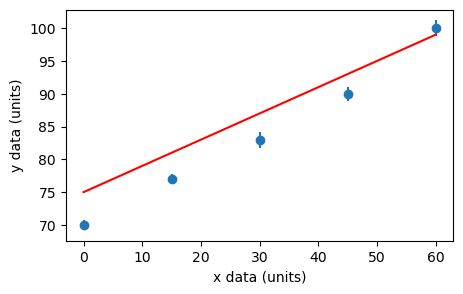

In [21]:
initial_values = numpy.array([0.4 , 75.0]) # Initial guess for fit parameters


plt.figure(figsize=(5,3))
plt.errorbar(x_values, 
             y_values, 
             yerr=y_errors, # use y_errors array for y error bars
             marker='o',    # circular markers at each datapoint
             linestyle='None') # no connecting lines

plt.plot(x_values, linear_model(x_values, initial_values), color='r')

plt.xlabel('x data (units)') # axis labels and units
plt.ylabel('y data (units)')
plt.show() 

This confirms that our starting point is reasonably close to the correct result.

---

We need to determine chi-squared. We define a function to calculate chi-squared, based on:
- the arbitrarily-sized array of model parameters `model_params` for which we wish to determine the chi-squared value
- the model function `model` which will be used
- our datapoint values and error-bars.

To illustrate the minimisation, we print the value of chi-squared each time the function is called... (note that 'printing' is very slow, so you do not want to do this other than as an example!)


In [22]:
def chi_squared(model_params, model, x_data, y_data, y_err):
    chi_sq = numpy.sum(((y_data - model(x_data, model_params))/y_err)**2)
    print(chi_sq)
    return chi_sq

As an example, and to test this, we can calculate the initial value of chi-squared at our starting parameters:

In [24]:
print('initial chi^2 = ', end='') # end='' to not start a new line - value printed by chi_squared function
initial_chi_squared = chi_squared(initial_values, linear_model, x_values, y_values, y_errors)

initial chi^2 = 90.95913330897096



---

The next step is to actually do the fitting - using `scipy.optimize.minimize` to adjust the parameter values, starting from `initial_values`, in order to minimise the result of the `chi_squared` function. The parameters passed as `args` are those to be passed to the `chi_squared` function in addition to the array of parameter values at each step in the minimisation.

In [25]:
fit = scipy.optimize.minimize(chi_squared, # the function to minimize
                              initial_values, # where in 'parameter space' to start from
                              args=(linear_model, x_values, y_values, y_errors)) # model function and data to use
                             
# Termination output message is fit.message - did the minimisation complete successfully?
print(fit.message)

90.95913330897096
90.95914152505203
90.95913392106412
4886.073323778855
4886.073173881197
4886.073320466631
76.39668868355669
76.39668865320444
76.39668909097672
49.96674129804334
49.96674127385455
49.96674162274451
12.064954374566309
12.064954364410607
12.064954510891551
3.9542011412754468
3.9542011412754543
3.9542011412754494
Optimization terminated successfully.


You should see a series of chi-squared values, printed by our `chi_squared` function each time it is called. The sets of 3 closely spaced values are being used by `scipy.optimize.minimize` to calculate the local gradient at various points in the 2D parameter space. We eventually reach an appropriate minimum, where the local gradient is sufficiently close to zero. 

You will learn more about optimisation algorithms in your Computational Physics course.

---

Assuming the minimisation terminated successfully (often it does not, using this approach for even slightly more complicated problems) we can look at the result of the fitting:

In [26]:
# minimized value for chi_squared function is fit.fun - not a call to chi_squared function!
print('minimised chi-squared = {}'.format(fit.fun))

# Resulting best fit parameter array is output as fit.x
slope, intercept = fit.x.copy()

print('best fit slope = {} units?'.format(slope))
print('best fit intercept = {} units?'.format(intercept))

# Take a moment at this point to think about significant figures...

minimised chi-squared = 3.9542011412754468
best fit slope = 0.4787473587660229 units?
best fit intercept = 69.70678015613197 units?


We will also calculate the minimized value of chi-squared again ; this time using the `chi_squared` function directly, and (a list containing) the best fit parameter values. The result should be the same as the result above...

In [28]:
print('chi^2_min = ', end='') # end='' to not start a new line - value printed by chi_squared function
chi_squared_min = chi_squared([slope, intercept], linear_model, x_values, y_values, y_errors)

chi^2_min = 3.9542011412754468


---

We can calculate the number of degrees-of-freedom by finding the number of elements in the data and fitted values arrays.

In [29]:
degrees_of_freedom = x_values.size - fit.x.size # Make sure you understand why!
print('DoF = {}'.format(degrees_of_freedom))

DoF = 3


We can also then calculate the reduced chi-squared associated with the best-fitting parameters, using the number of degrees-of-freedom determined previously.

In [30]:
reduced_chi_squared = chi_squared_min/degrees_of_freedom
print('reduced chi^2 = {}'.format(reduced_chi_squared))

reduced chi^2 = 1.3180670470918157


Next, we can calculate the 'P-value'. ``scipy.stats.chi2.sf`` is the Python equivalent of the ``chidist`` function in Excel. 

In [31]:
P_value = scipy.stats.chi2.sf(chi_squared_min, degrees_of_freedom)
print('P(chi^2_min, DoF) = {}'.format(P_value))

P(chi^2_min, DoF) = 0.26645223635948995



---

Assuming that the reduced chi-squared for the fit provides a value indicating that our model **is** an **acceptably good description** of our data, we should inspect a plot of the fit against the data to check that this is indeed the case.

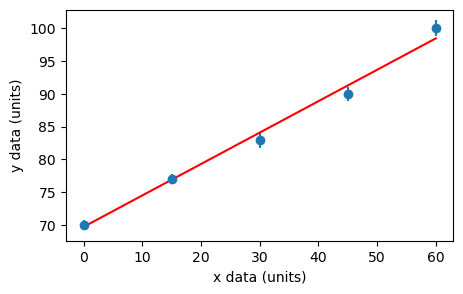

In [32]:
plt.figure(figsize=(5,3))
plt.errorbar(x_values, 
             y_values, 
             yerr=y_errors, 
             marker='o', 
             linestyle='None')

plt.xlabel('x data (units)') # Axis labels
plt.ylabel('y data (units)')

# Generate best fit using model function and best fit parameters, and add to plot
plt.plot(x_values, 
         linear_model(x_values, [slope, intercept]), 
         color='r')

plt.show()

The combination of the reduced chi-squared value, the P-value, and inspection of the fit against the data (you may like to add a normalised residual plot yourself...) should enable you to determine whether or not the model provides an appropriate description of the data.

In principle we can also determine the uncertainties in the parameters from the 'Hessian' matrix which is generated by `scipy.optimize.minimize` - but we will not do this here, since we will never be using this exact approach to fit our data!

---

We have seen that we can fit a line through some data by directly minimising chi-squared in Python. This approach is not robust for anythin other than the simplest of problems - a small number of fitting parameters, all with values of a similar order of magnitide. 

A more robust approach, which 'hides' the chi-squared minimisation under the hood, is outlined in the separate notebook `example_curve_fit.ipynb`.